# TRUSTSR Lab 01.2 — Systematic Missing-Edge Experiments

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Lab status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Objective

Systematically remove each dependency edge from the synthetic ground-truth Causal State Graph (CSG), measure the effect on reachability-based contamination analysis, rank edges by impact, and test combinations of missing edges.

**This notebook is a synthetic simulation.** It does not use real agent traces, infer real causal dependencies, detect poisoning, or validate production effectiveness.

## Research questions

1. Which single missing edge causes the largest number of false negatives?
2. How does the false-negative rate change when multiple edges are missing?
3. Do the experiment outputs match the declared synthetic ground truth?

## Definitions

- **Ground-truth graph:** The full, fixed graph defined below. It is never modified.
- **Observed graph:** A copy of the ground-truth graph with one or more edges removed.
- **Expected affected descendants:** Descendants of the declared poison source in the unchanged ground-truth graph.
- **False negative (FN):** An expected affected descendant not flagged by reachability in the observed graph.
- **False-negative rate (FNR):** `FN / number of expected affected descendants`.
- **Edge impact rank:** Ranking by false-negative count, then false-negative rate. Ties are retained; the rank is descriptive for this graph only.

No numerical result in this notebook should be presented as empirical evidence from real-world agent systems.

## 1. Environment setup

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys
import platform
from datetime import datetime, timezone
from itertools import combinations

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1
Pandas: 3.0.2
Execution timestamp (UTC): 2026-10-11T10:26:24.950400+00:00


## 2. Define the fixed synthetic ground-truth graph

This scenario intentionally matches Labs 01 and 01.1. Edge direction is `source → dependent state`. The ground-truth graph remains unchanged throughout every experiment.

In [3]:
states = [
    {"id": "M1", "label": "Trusted project requirement", "kind": "memory", "status": "trusted"},
    {"id": "M2", "label": "Poisoned memory: unsafe instruction", "kind": "memory", "status": "poisoned"},
    {"id": "D1", "label": "Planning decision A", "kind": "decision", "status": "normal"},
    {"id": "D2", "label": "Planning decision B", "kind": "decision", "status": "normal"},
    {"id": "P1", "label": "Execution plan A", "kind": "plan", "status": "normal"},
    {"id": "P2", "label": "Execution plan B", "kind": "plan", "status": "normal"},
    {"id": "A1", "label": "Derived action record", "kind": "action", "status": "normal"},
    {"id": "S1", "label": "Independent status note", "kind": "state", "status": "normal"},
]
dependencies = [
    ("M1", "D1"),
    ("M2", "D1"),
    ("D1", "P1"),
    ("P1", "A1"),
    ("M2", "D2"),
    ("D2", "P2"),
    ("M1", "S1"),
]
POISON_SOURCE = "M2"

G_truth = nx.DiGraph()
for state in states:
    G_truth.add_node(state["id"], **state)
G_truth.add_edges_from(dependencies)

assert nx.is_directed_acyclic_graph(G_truth)
expected_affected = set(nx.descendants(G_truth, POISON_SOURCE))
all_edges = sorted(G_truth.edges())

print("Nodes:", G_truth.number_of_nodes())
print("Edges:", G_truth.number_of_edges())
print("Poison source:", POISON_SOURCE)
print("Expected affected descendants:", sorted(expected_affected))
print("Expected affected count:", len(expected_affected))
print("Edges tested individually:", len(all_edges))

display(pd.DataFrame(all_edges, columns=["source", "dependent"]))

Nodes: 8
Edges: 7
Poison source: M2
Expected affected descendants: ['A1', 'D1', 'D2', 'P1', 'P2']
Expected affected count: 5
Edges tested individually: 7


  source dependent
0     D1        P1
1     D2        P2
2     M1        D1
3     M1        S1
4     M2        D1
5     M2        D2
6     P1        A1

## 3. Define a reusable analysis function

Each test creates a fresh copy of the fixed ground-truth graph. The function removes only the requested edges, computes descendants from the same declared poison source, and compares flagged nodes with the unchanged expected affected set.

In [4]:
def evaluate_missing_edges(edges_to_remove):
    """Evaluate reachability after removing edges from a copy of ground truth."""
    edges_to_remove = tuple(tuple(edge) for edge in edges_to_remove)
    observed = G_truth.copy()

    for edge in edges_to_remove:
        if not observed.has_edge(*edge):
            raise ValueError(f"Edge is absent or already removed: {edge}")
        observed.remove_edge(*edge)

    flagged = set(nx.descendants(observed, POISON_SOURCE))
    false_negatives = expected_affected - flagged
    false_positives = flagged - expected_affected
    denominator = len(expected_affected)

    return {
        "removed_edges": "; ".join(f"{u}->{v}" for u, v in edges_to_remove) or "(none)",
        "removed_edge_count": len(edges_to_remove),
        "expected_affected_count": denominator,
        "flagged_expected_count": len(flagged & expected_affected),
        "false_negative_count": len(false_negatives),
        "false_negative_rate": len(false_negatives) / denominator if denominator else float("nan"),
        "false_positive_count": len(false_positives),
        "false_negatives": sorted(false_negatives),
        "false_positives": sorted(false_positives),
        "flagged_nodes": sorted(flagged),
    }

baseline = evaluate_missing_edges([])
print("Baseline result:")
display(pd.DataFrame([baseline])[[
    "removed_edges", "expected_affected_count", "flagged_expected_count",
    "false_negative_count", "false_negative_rate", "false_positive_count"
]])

assert baseline["false_negative_count"] == 0
assert baseline["false_positive_count"] == 0

Baseline result:


  removed_edges  expected_affected_count  flagged_expected_count  false_negative_count  false_negative_rate  false_positive_count
0        (none)                        5                       5                     0                  0.0                     0

## 4. Remove each edge individually

Every dependency edge is removed once, one experiment at a time. The ground-truth graph and expected affected descendants remain unchanged across all tests.

In [5]:
single_edge_results = []

for edge in all_edges:
    result = evaluate_missing_edges([edge])
    result["removed_edge_source"] = edge[0]
    result["removed_edge_dependent"] = edge[1]
    result["edge_label"] = f"{edge[0]} -> {edge[1]}"
    single_edge_results.append(result)

single_edge_df = pd.DataFrame(single_edge_results)
single_edge_df = single_edge_df.sort_values(
    ["false_negative_count", "false_negative_rate", "edge_label"],
    ascending=[False, False, True]
).reset_index(drop=True)
single_edge_df["impact_rank"] = (
    single_edge_df[["false_negative_count", "false_negative_rate"]]
    .apply(tuple, axis=1)
    .rank(method="min", ascending=False)
    .astype(int)
)

display(single_edge_df[[
    "impact_rank", "edge_label", "false_negative_count",
    "false_negative_rate", "false_negatives", "false_positive_count"
]])

   impact_rank edge_label  false_negative_count  false_negative_rate false_negatives  false_positive_count
0            1   M2 -> D1                     3                  0.6    [A1, D1, P1]                     0
1            2   D1 -> P1                     2                  0.4        [A1, P1]                     0
2            2   M2 -> D2                     2                  0.4        [D2, P2]                     0
3            4   D2 -> P2                     1                  0.2            [P2]                     0
4            4   P1 -> A1                     1                  0.2            [A1]                     0
5            6   M1 -> D1                     0                  0.0              []                     0
6            6   M1 -> S1                     0                  0.0              []                     0

## 5. Plot single-edge impact

The chart ranks the edges by the number of expected affected descendants missed in this synthetic graph. It is not a general ranking of edge importance across real systems.

Highest-impact edge(s) in this scenario:


   impact_rank edge_label  false_negative_count  false_negative_rate false_negatives
0            1   M2 -> D1                     3                  0.6    [A1, D1, P1]

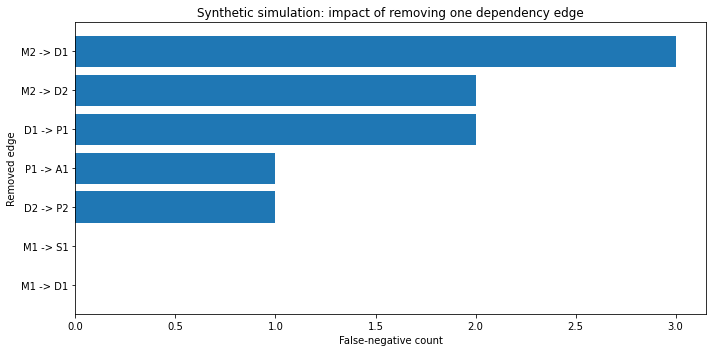

In [6]:
plot_df = single_edge_df.sort_values(
    ["false_negative_count", "edge_label"],
    ascending=[True, True]
)

plt.figure(figsize=(10, 5))
plt.barh(plot_df["edge_label"], plot_df["false_negative_count"])
plt.xlabel("False-negative count")
plt.ylabel("Removed edge")
plt.title("Synthetic simulation: impact of removing one dependency edge")
plt.tight_layout()
plt.show()

print("Highest-impact edge(s) in this scenario:")
max_fn = single_edge_df["false_negative_count"].max()
display(single_edge_df.loc[
    single_edge_df["false_negative_count"] == max_fn,
    ["impact_rank", "edge_label", "false_negative_count", "false_negative_rate", "false_negatives"]
])

## 6. Multiple-edge-removal experiments

This section tests every pair of missing edges (all 2-edge combinations) and then a small set of predeclared higher-severity cases. These are controlled fault-injection scenarios, not estimates of real-world failure probabilities.

In [7]:
pair_results = []
for edge_pair in combinations(all_edges, 2):
    result = evaluate_missing_edges(edge_pair)
    pair_results.append(result)

pair_df = pd.DataFrame(pair_results).sort_values(
    ["false_negative_count", "false_negative_rate", "removed_edges"],
    ascending=[False, False, True]
).reset_index(drop=True)

print("Number of two-edge combinations tested:", len(pair_df))
display(pair_df[[
    "removed_edges", "removed_edge_count", "false_negative_count",
    "false_negative_rate", "false_negatives", "false_positive_count"
]].head(10))

# Predeclared illustrative stress scenarios.
stress_scenarios = {
    "Remove all edges out of M2": [("M2", "D1"), ("M2", "D2")],
    "Remove the D1 downstream chain": [("D1", "P1"), ("P1", "A1")],
    "Remove both branch-entry edges": [("M2", "D1"), ("M2", "D2")],
    "Remove two independent-branch edges": [("M1", "D1"), ("M1", "S1")],
}

stress_results = []
for name, removed in stress_scenarios.items():
    result = evaluate_missing_edges(removed)
    result["scenario_name"] = name
    stress_results.append(result)

stress_df = pd.DataFrame(stress_results)
display(stress_df[[
    "scenario_name", "removed_edges", "false_negative_count",
    "false_negative_rate", "false_negatives", "false_positive_count"
]])

Number of two-edge combinations tested: 21


    removed_edges  removed_edge_count  false_negative_count  false_negative_rate       false_negatives  false_positive_count
0  M2->D1; M2->D2                   2                     5                  1.0  [A1, D1, D2, P1, P2]                     0
1  D1->P1; M2->D2                   2                     4                  0.8      [A1, D2, P1, P2]                     0
2  D2->P2; M2->D1                   2                     4                  0.8      [A1, D1, P1, P2]                     0
3  D1->P1; D2->P2                   2                     3                  0.6          [A1, P1, P2]                     0
4  D1->P1; M2->D1                   2                     3                  0.6          [A1, D1, P1]                     0
5  M1->D1; M2->D1                   2                     3                  0.6          [A1, D1, P1]                     0
6  M1->S1; M2->D1                   2                     3                  0.6          [A1, D1, P1]                     0


                         scenario_name   removed_edges  false_negative_count  false_negative_rate       false_negatives  false_positive_count
0           Remove all edges out of M2  M2->D1; M2->D2                     5                  1.0  [A1, D1, D2, P1, P2]                     0
1       Remove the D1 downstream chain  D1->P1; P1->A1                     2                  0.4              [A1, P1]                     0
2       Remove both branch-entry edges  M2->D1; M2->D2                     5                  1.0  [A1, D1, D2, P1, P2]                     0
3  Remove two independent-branch edges  M1->D1; M1->S1                     0                  0.0                    []                     0

## 7. Plot false-negative rate for all two-edge combinations

Minimum pair FNR: 0.0
Maximum pair FNR: 1.0
Mean pair FNR: 0.467


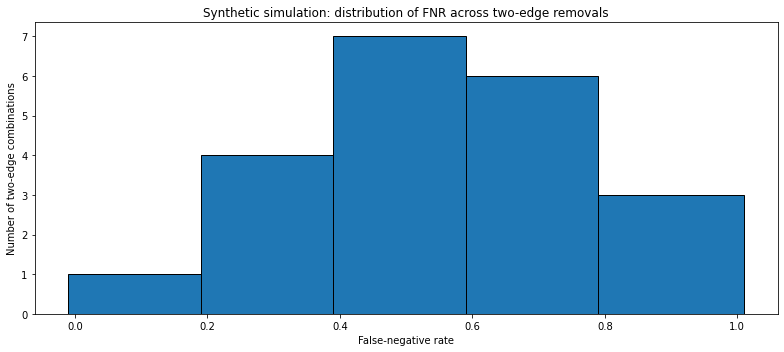

In [8]:
plt.figure(figsize=(11, 5))
plt.hist(pair_df["false_negative_rate"], bins=[-0.01, 0.19, 0.39, 0.59, 0.79, 1.01], edgecolor="black")
plt.xlabel("False-negative rate")
plt.ylabel("Number of two-edge combinations")
plt.title("Synthetic simulation: distribution of FNR across two-edge removals")
plt.tight_layout()
plt.show()

print("Minimum pair FNR:", round(float(pair_df["false_negative_rate"].min()), 3))
print("Maximum pair FNR:", round(float(pair_df["false_negative_rate"].max()), 3))
print("Mean pair FNR:", round(float(pair_df["false_negative_rate"].mean()), 3))

## 8. Assertions and consistency checks

These assertions validate the experiment implementation against the constructed graph. They are not proof of real-world performance.

In [9]:
# Ground-truth graph and expected affected states remain unchanged.
assert G_truth.number_of_edges() == 7
assert expected_affected == {"D1", "D2", "P1", "P2", "A1"}

# One test exists for each graph edge.
assert len(single_edge_df) == len(all_edges) == 7
assert single_edge_df["edge_label"].nunique() == 7

# Baseline has no false negatives or false positives.
assert baseline["false_negative_count"] == 0
assert baseline["false_positive_count"] == 0

# Removing D1 -> P1 must miss P1 and A1 in this graph.
target = evaluate_missing_edges([("D1", "P1")])
assert set(target["false_negatives"]) == {"P1", "A1"}
assert target["false_negative_count"] == 2
assert abs(target["false_negative_rate"] - 0.4) < 1e-12

# Pair experiment tests every unique 2-edge combination.
assert len(pair_df) == len(list(combinations(all_edges, 2))) == 21
assert (pair_df["removed_edge_count"] == 2).all()
assert pair_df["false_negative_count"].between(0, len(expected_affected)).all()
assert pair_df["false_negative_rate"].between(0, 1).all()

# The source itself is excluded from descendants and cannot be a false positive.
assert all(POISON_SOURCE not in nodes for nodes in single_edge_df["flagged_nodes"])

print("PASS: fixed ground truth remains intact.")
print("PASS: all 7 single-edge removals evaluated.")
print("PASS: known D1 -> P1 failure reproduces 2 false negatives / 40% FNR.")
print("PASS: all 21 two-edge combinations evaluated.")
print("PASS: metric bounds and source-exclusion checks passed.")
print("All Lab 01.2 assertions passed.")

PASS: fixed ground truth remains intact.
PASS: all 7 single-edge removals evaluated.
PASS: known D1 -> P1 failure reproduces 2 false negatives / 40% FNR.
PASS: all 21 two-edge combinations evaluated.
PASS: metric bounds and source-exclusion checks passed.
All Lab 01.2 assertions passed.


## 9. Export results to CSV

The CSV files are generated from this run and can be used to inspect or archive the synthetic experiment.

In [10]:
single_edge_df.to_csv("trustsr_lab01_2_single_edge_results.csv", index=False)
pair_df.to_csv("trustsr_lab01_2_two_edge_combinations.csv", index=False)
stress_df.to_csv("trustsr_lab01_2_stress_scenarios.csv", index=False)

print("Generated files:")
print("- trustsr_lab01_2_single_edge_results.csv")
print("- trustsr_lab01_2_two_edge_combinations.csv")
print("- trustsr_lab01_2_stress_scenarios.csv")

Generated files:
- trustsr_lab01_2_single_edge_results.csv
- trustsr_lab01_2_two_edge_combinations.csv
- trustsr_lab01_2_stress_scenarios.csv


## 10. Interpretation and limitations

### What this lab provides

- A systematic test of every single dependency-edge removal in this fixed graph.
- A ranking of edges by false-negative impact in this graph.
- An exhaustive evaluation of all two-edge-removal combinations for the graph's seven edges.
- Several named stress scenarios.
- Reproducible CSV outputs and assertions.

### What it does not provide

- Real-world rates of missing provenance or dependencies.
- A real poison detector or a causal-edge discovery algorithm.
- Recovery, containment, or comparison with full rollback.
- Evidence that the same edge ranking applies to other graphs or agent architectures.
- Support for the monograph's numerical claims about work preservation, contamination, or blast radius.

### Reporting rule

Describe every output as a **synthetic simulation result**. To move toward empirical evidence, the next step is to define a realistic trace-generation procedure or a validated dataset with defensible ground truth, then evaluate the algorithm on those traces.

**Next lab candidate:** Conservative handling of unknown dependencies—measure whether flagging uncertain branches reduces false negatives and how many extra states it quarantines.